In [2]:


import pandas as pd
import numpy as np
import plotly.graph_objects as go
import plotly.express as px

from plotly.subplots import make_subplots
from google.colab import files


print("Please upload your CSV or Excel dataset")

uploaded = files.upload()

filename = list(uploaded.keys())[0]

if filename.lower().endswith(".csv"):
    df = pd.read_csv(filename)

elif filename.lower().endswith((".xlsx", ".xls")):
    df = pd.read_excel(filename)

else:
    raise ValueError("Please upload a CSV or Excel file.")


print("\nDataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

display(df.head())




df.columns = df.columns.str.strip()

print("\nColumns:")
print(df.columns.tolist())



# If your dataset has "Post Type" instead of "Post_Type"
if 'Post Type' in df.columns and 'Post_Type' not in df.columns:
    df.rename(columns={'Post Type': 'Post_Type'}, inplace=True)

# If your dataset has "Engagement_Rate"
if 'Engagement_Rate' in df.columns and 'Engagement Rate' not in df.columns:
    df.rename(columns={'Engagement_Rate': 'Engagement Rate'}, inplace=True)

# If your dataset has "Total_Engagement"
if 'Total_Engagement' in df.columns and 'Total Engagement' not in df.columns:
    df.rename(columns={'Total_Engagement': 'Total Engagement'}, inplace=True)



if 'Date' in df.columns:

    df['Date'] = pd.to_datetime(
        df['Date'],
        errors='coerce'
    )



numeric_columns = [
    'Views',
    'Likes',
    'Comments',
    'Shares',
    'Followers',
    'Engagement Rate',
    'Total Engagement'
]

for col in numeric_columns:

    if col in df.columns:

        df[col] = pd.to_numeric(
            df[col],
            errors='coerce'
        )



# Total Engagement = Likes + Comments + Shares

if 'Total Engagement' not in df.columns:

    df['Total Engagement'] = (
        df['Likes'].fillna(0)
        + df['Comments'].fillna(0)
        + df['Shares'].fillna(0)
    )

else:

    df['Total Engagement'] = df['Total Engagement'].fillna(
        df['Likes'].fillna(0)
        + df['Comments'].fillna(0)
        + df['Shares'].fillna(0)
    )



if 'Engagement Rate' not in df.columns:

    df['Engagement Rate'] = np.where(

        df['Views'] > 0,

        (df['Total Engagement'] / df['Views']) * 100,

        0
    )



df = df.dropna(
    subset=['Platform']
).copy()


print("\n======================================")
print("DATA PREPARATION COMPLETED")
print("======================================")

print("Rows:", len(df))

display(df.head())



total_views = df['Views'].sum()

total_likes = df['Likes'].sum()

total_engagement = df['Total Engagement'].sum()


print("\n======================================")
print("KPI VALUES")
print("======================================")

print(
    f"Total Views       : {total_views:,.0f}"
)

print(
    f"Total Likes       : {total_likes:,.0f}"
)

print(
    f"Total Engagement  : {total_engagement:,.0f}"
)




platform_engagement = (

    df.groupby('Platform')['Total Engagement']

    .sum()

    .reset_index()

    .sort_values(
        'Total Engagement',
        ascending=False
    )
)


# ============================================================
# 13. AVERAGE ENGAGEMENT RATE BY PLATFORM
# ============================================================

average_engagement_rate = (

    df.groupby('Platform')['Engagement Rate']

    .mean()

    .reset_index()

    .sort_values(
        'Engagement Rate',
        ascending=False
    )
)


# ============================================================
# 14. TOTAL ENGAGEMENT BY POST TYPE
# ============================================================

post_type_engagement = (

    df.groupby('Post_Type')['Total Engagement']

    .sum()

    .reset_index()

    .sort_values(
        'Total Engagement',
        ascending=False
    )
)


# ============================================================
# 15. FOLLOWERS BY PLATFORM
# ============================================================

followers_platform = (

    df.groupby('Platform')['Followers']

    .sum()

    .reset_index()

    .sort_values(
        'Followers',
        ascending=False
    )
)


# ============================================================
# 16. TOTAL ENGAGEMENT BY DATE
# ============================================================

date_engagement = (

    df.groupby('Date')['Total Engagement']

    .sum()

    .reset_index()

    .sort_values('Date')
)


# ============================================================
# 17. COMMENTS AND SHARES BY PLATFORM
# ============================================================

comments_shares = (

    df.groupby('Platform')[['Comments', 'Shares']]

    .sum()

    .reset_index()
)


# ============================================================
# 18. CREATE DASHBOARD
# ============================================================

fig = make_subplots(

    rows=4,
    cols=3,

    specs=[

        # ==============================================
        # ROW 1 - THREE KPI CARDS
        # ==============================================
        [
            {'type': 'indicator'},
            {'type': 'indicator'},
            {'type': 'indicator'}
        ],

        # ==============================================
        # ROW 2
        # Engagement by Platform
        # Average Engagement Rate
        # Donut
        # ==============================================
        [
            {'type': 'xy'},
            {'type': 'xy'},
            {'type': 'domain'}
        ],

        # ==============================================
        # ROW 3
        # Treemap
        # Line chart spans 2 columns
        # ==============================================
        [
            {'type': 'domain'},
            {'type': 'xy', 'colspan': 2},
            None
        ],

        # ==============================================
        # ROW 4
        # Comments + Shares spans 3 columns
        # ==============================================
        [
            {'type': 'xy', 'colspan': 3},
            None,
            None
        ]
    ],

    column_widths=[
        0.33,
        0.33,
        0.33
    ],

    row_heights=[
        0.15,
        0.28,
        0.28,
        0.29
    ],

    vertical_spacing=0.08,

    horizontal_spacing=0.06
)


# ============================================================
# 19. KPI 1 - TOTAL VIEWS
# ============================================================

fig.add_trace(

    go.Indicator(

        mode='number',

        value=total_views,

        title={
            'text': '<b>SUM OF VIEWS</b>'
        },

        number={
            'valueformat': ',.0f'
        }

    ),

    row=1,
    col=1
)


# ============================================================
# 20. KPI 2 - TOTAL LIKES
# ============================================================

fig.add_trace(

    go.Indicator(

        mode='number',

        value=total_likes,

        title={
            'text': '<b>SUM OF LIKES</b>'
        },

        number={
            'valueformat': ',.0f'
        }

    ),

    row=1,
    col=2
)


# ============================================================
# 21. KPI 3 - TOTAL ENGAGEMENT
# ============================================================

fig.add_trace(

    go.Indicator(

        mode='number',

        value=total_engagement,

        title={
            'text': '<b>SUM OF TOTAL ENGAGEMENT</b>'
        },

        number={
            'valueformat': ',.0f'
        }

    ),

    row=1,
    col=3
)


# ============================================================
# 22. TOTAL ENGAGEMENT BY PLATFORM
# ============================================================

fig.add_trace(

    go.Bar(

        x=platform_engagement['Platform'],

        y=platform_engagement['Total Engagement'],

        name='Total Engagement',

        text=platform_engagement['Total Engagement'],

        texttemplate='%{text:,.0f}',

        textposition='outside',

        hovertemplate=
        '<b>%{x}</b><br>' +
        'Total Engagement: %{y:,.0f}' +
        '<extra></extra>'

    ),

    row=2,
    col=1
)


# ============================================================
# 23. AVERAGE ENGAGEMENT RATE
# ============================================================

fig.add_trace(

    go.Bar(

        x=average_engagement_rate['Platform'],

        y=average_engagement_rate['Engagement Rate'],

        name='Average Engagement Rate',

        text=average_engagement_rate['Engagement Rate'],

        texttemplate='%{text:.2f}',

        textposition='outside',

        hovertemplate=
        '<b>%{x}</b><br>' +
        'Average Engagement Rate: %{y:.2f}' +
        '<extra></extra>'

    ),

    row=2,
    col=2
)


# ============================================================
# 24. DONUT - TOTAL ENGAGEMENT BY POST TYPE
# ============================================================

fig.add_trace(

    go.Pie(

        labels=post_type_engagement['Post_Type'],

        values=post_type_engagement['Total Engagement'],

        hole=0.55,

        textinfo='percent',

        name='Post Type',

        hovertemplate=
        '<b>%{label}</b><br>' +
        'Engagement: %{value:,.0f}<br>' +
        '%{percent}' +
        '<extra></extra>'

    ),

    row=2,
    col=3
)


# ============================================================
# 25. FOLLOWERS BY PLATFORM - TREEMAP
# ============================================================

fig.add_trace(

    go.Treemap(

        labels=followers_platform['Platform'],

        parents=[
            ''
        ] * len(followers_platform),

        values=followers_platform['Followers'],

        name='Followers',

        textinfo='label+value',

        hovertemplate=
        '<b>%{label}</b><br>' +
        'Followers: %{value:,.0f}' +
        '<extra></extra>'

    ),

    row=3,
    col=1
)


# ============================================================
# 26. TOTAL ENGAGEMENT BY DATE
# ============================================================

fig.add_trace(

    go.Scatter(

        x=date_engagement['Date'],

        y=date_engagement['Total Engagement'],

        mode='lines',

        name='Total Engagement',

        line={
            'width': 3
        },

        hovertemplate=
        '<b>%{x|%d %b %Y}</b><br>' +
        'Engagement: %{y:,.0f}' +
        '<extra></extra>'

    ),

    row=3,
    col=2
)


# ============================================================
# 27. COMMENTS BY PLATFORM
# ============================================================

fig.add_trace(

    go.Bar(

        x=comments_shares['Platform'],

        y=comments_shares['Comments'],

        name='Comments',

        marker={
            'opacity': 0.8
        },

        hovertemplate=
        '<b>%{x}</b><br>' +
        'Comments: %{y:,.0f}' +
        '<extra></extra>'

    ),

    row=4,
    col=1
)


# ============================================================
# 28. SHARES BY PLATFORM
# ============================================================

fig.add_trace(

    go.Bar(

        x=comments_shares['Platform'],

        y=comments_shares['Shares'],

        name='Shares',

        marker={
            'opacity': 0.8
        },

        hovertemplate=
        '<b>%{x}</b><br>' +
        'Shares: %{y:,.0f}' +
        '<extra></extra>'

    ),

    row=4,
    col=1
)


# ============================================================
# 29. AXIS TITLES
# ============================================================

# Engagement by Platform
fig.update_xaxes(
    title_text='Platform',
    row=2,
    col=1
)

fig.update_yaxes(
    title_text='Total Engagement',
    row=2,
    col=1
)


# Average Engagement Rate
fig.update_xaxes(
    title_text='Platform',
    row=2,
    col=2
)

fig.update_yaxes(
    title_text='Engagement Rate',
    row=2,
    col=2
)


# Date chart
fig.update_xaxes(
    title_text='Date',
    row=3,
    col=2
)

fig.update_yaxes(
    title_text='Total Engagement',
    row=3,
    col=2
)


# Comments and Shares
fig.update_xaxes(
    title_text='Platform',
    row=4,
    col=1
)

fig.update_yaxes(
    title_text='Count',
    row=4,
    col=1
)


# ============================================================
# 30. CHART TITLES
# ============================================================

# Row 2 titles
fig.add_annotation(
    text='<b>Total Engagement by Platform</b>',
    x=0.16,
    y=0.82,
    xref='paper',
    yref='paper',
    showarrow=False
)

fig.add_annotation(
    text='<b>Average Engagement Rate by Platform</b>',
    x=0.50,
    y=0.82,
    xref='paper',
    yref='paper',
    showarrow=False
)

fig.add_annotation(
    text='<b>Total Engagement by Post Type</b>',
    x=0.84,
    y=0.82,
    xref='paper',
    yref='paper',
    showarrow=False
)


# Row 3 titles
fig.add_annotation(
    text='<b>Followers by Platform</b>',
    x=0.16,
    y=0.535,
    xref='paper',
    yref='paper',
    showarrow=False
)

fig.add_annotation(
    text='<b>Total Engagement by Date</b>',
    x=0.67,
    y=0.535,
    xref='paper',
    yref='paper',
    showarrow=False
)


# Row 4 title
fig.add_annotation(
    text='<b>Comments and Shares by Platform</b>',
    x=0.50,
    y=0.265,
    xref='paper',
    yref='paper',
    showarrow=False
)


# ============================================================
# 31. DASHBOARD TITLE
# ============================================================

fig.update_layout(

    title={
        'text':
        '<b>SOCIAL MEDIA ANALYTICS DASHBOARD</b>',

        'x': 0.5,

        'xanchor': 'center',

        'font': {
            'size': 26
        }
    },

    height=1100,

    width=1400,

    template='plotly_white',

    hovermode='x unified',

    margin={
        'l': 50,
        'r': 50,
        't': 100,
        'b': 50
    },

    legend={
        'orientation': 'h',

        'yanchor': 'bottom',

        'y': -0.05,

        'xanchor': 'center',

        'x': 0.5
    }
)


# ============================================================
# 32. SHOW DASHBOARD
# ============================================================

fig.show()


# ============================================================
# 33. PLATFORM SUMMARY TABLE
# ============================================================

summary = (

    df.groupby('Platform')

    .agg(

        Views=('Views', 'sum'),

        Likes=('Likes', 'sum'),

        Comments=('Comments', 'sum'),

        Shares=('Shares', 'sum'),

        Followers=('Followers', 'sum'),

        Total_Engagement=(
            'Total Engagement',
            'sum'
        ),

        Average_Engagement_Rate=(
            'Engagement Rate',
            'mean'
        )

    )

    .reset_index()

)


print("\n======================================")
print("PLATFORM SUMMARY")
print("======================================")

display(summary)

Please upload your CSV or Excel dataset


Saving social_media_data.csv to social_media_data (1).csv

Dataset loaded successfully!
Rows: 50
Columns: 9


,Post_ID,Platform,Post_Type,Date,Likes,Comments,Shares,Views,Followers
0,1,Instagram,Reel,2026-01-03,5200,310,480,52000,12000
1,2,YouTube,Video,2026-01-08,7100,520,620,82000,25000
2,3,Facebook,Video,2026-01-12,3400,190,260,43000,18000
3,4,Instagram,Image,2026-01-18,2300,120,140,28000,12000
4,5,LinkedIn,Post,2026-01-25,1200,85,70,15000,9000



Columns:
['Post_ID', 'Platform', 'Post_Type', 'Date', 'Likes', 'Comments', 'Shares', 'Views', 'Followers']

DATA PREPARATION COMPLETED
Rows: 50


,Post_ID,Platform,Post_Type,Date,Likes,Comments,Shares,Views,Followers,Total Engagement,Engagement Rate
0,1,Instagram,Reel,2026-01-03,5200,310,480,52000,12000,5990,11.519231
1,2,YouTube,Video,2026-01-08,7100,520,620,82000,25000,8240,10.048780
2,3,Facebook,Video,2026-01-12,3400,190,260,43000,18000,3850,8.953488
3,4,Instagram,Image,2026-01-18,2300,120,140,28000,12000,2560,9.142857
4,5,LinkedIn,Post,2026-01-25,1200,85,70,15000,9000,1355,9.033333



KPI VALUES
Total Views       : 3,106,500
Total Likes       : 265,450
Total Engagement  : 306,850



PLATFORM SUMMARY


,Platform,Views,Likes,Comments,Shares,Followers,Total_Engagement,Average_Engagement_Rate
0,Facebook,540000,43000,2635,3385,198000,49020,8.949427
1,Instagram,878000,86200,5180,7175,192000,98555,10.766730
2,LinkedIn,227500,18950,1365,1150,90000,21465,9.369275
3,YouTube,1461000,117300,9330,11180,325000,137810,9.518211


SOCIAL MEDIA ANALYTICS

Original Columns:
['Post_ID', 'Platform', 'Post_Type', 'Date', 'Likes', 'Comments', 'Shares', 'Views', 'Followers']

Dataset Shape: (50, 9)


,Post_ID,Platform,Post_Type,Date,Likes,Comments,Shares,Views,Followers
0,1,Instagram,Reel,2026-01-03,5200,310,480,52000,12000
1,2,YouTube,Video,2026-01-08,7100,520,620,82000,25000
2,3,Facebook,Video,2026-01-12,3400,190,260,43000,18000
3,4,Instagram,Image,2026-01-18,2300,120,140,28000,12000
4,5,LinkedIn,Post,2026-01-25,1200,85,70,15000,9000



Cleaned Columns:
['Post_ID', 'Platform', 'Post_Type', 'Date', 'Likes', 'Comments', 'Shares', 'Views', 'Followers']

MISSING VALUES
Post_ID      0
Platform     0
Post_Type    0
Date         0
Likes        0
Comments     0
Shares       0
Views        0
Followers    0
dtype: int64

Duplicate Rows: 0
Rows after removing duplicates: 50

AVAILABLE COLUMNS
- Post_ID
- Platform
- Post_Type
- Date
- Likes
- Comments
- Shares
- Views
- Followers

Total Engagement column not found.
Creating Total Engagement from Likes + Comments + Shares...
Engagement Rate column not found.
Creating Engagement Rate...

KPI VALUES
Total Views              : 3,106,500
Total Likes              : 265,450
Total Comments           : 18,510
Total Shares             : 22,890
Total Engagement         : 306,850
Total Followers          : 805,000
Total Posts              : 50
Average Engagement Rate  : 9.76
Average Views            : 62130.0
Average Followers        : 16100.0
Average Engagement       : 6137.0

DESCRIPTIVE 

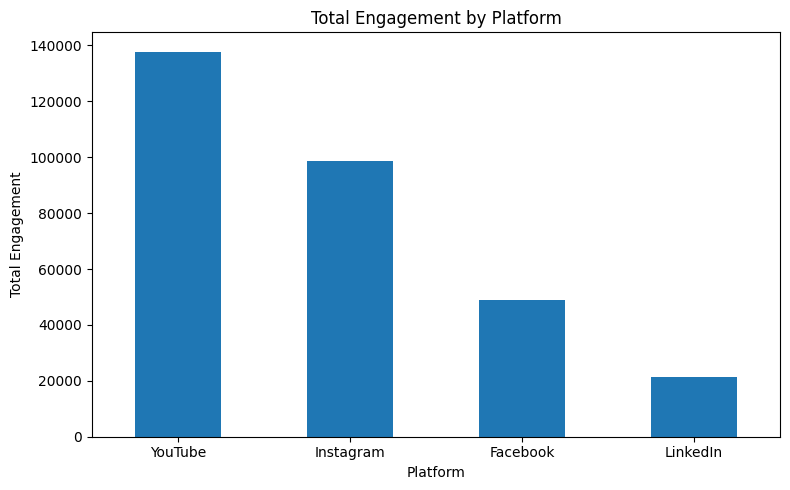

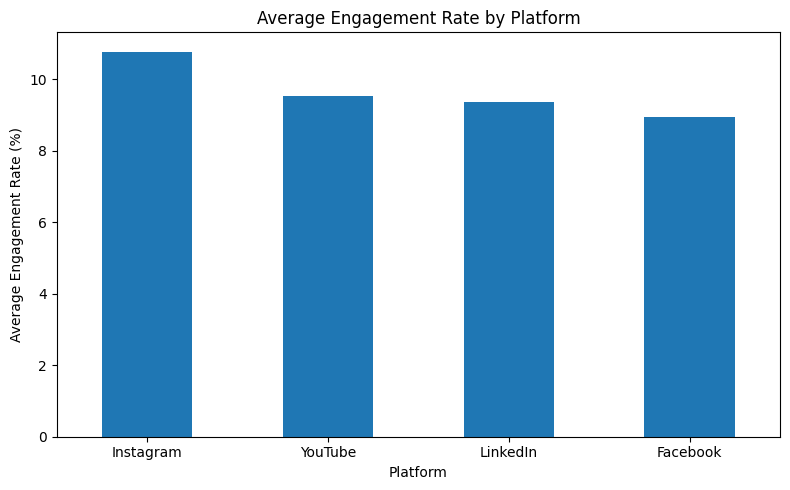

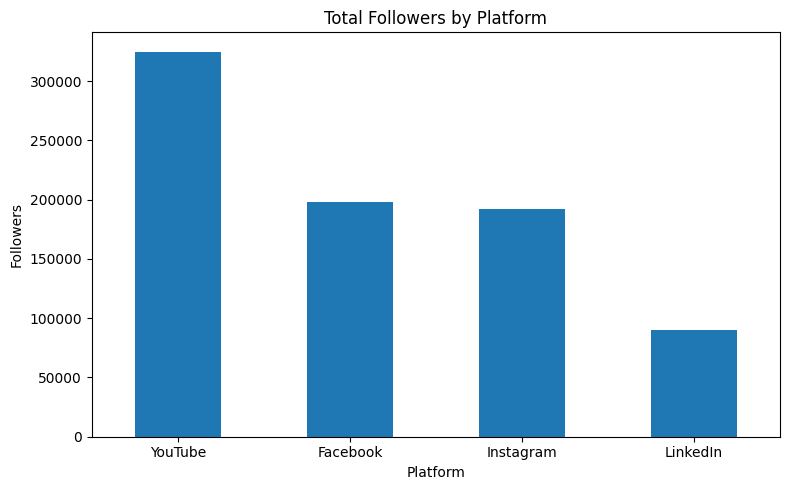

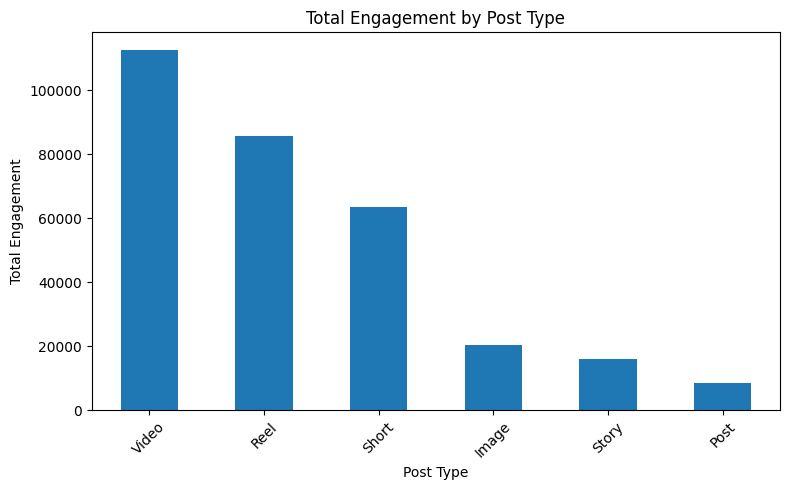

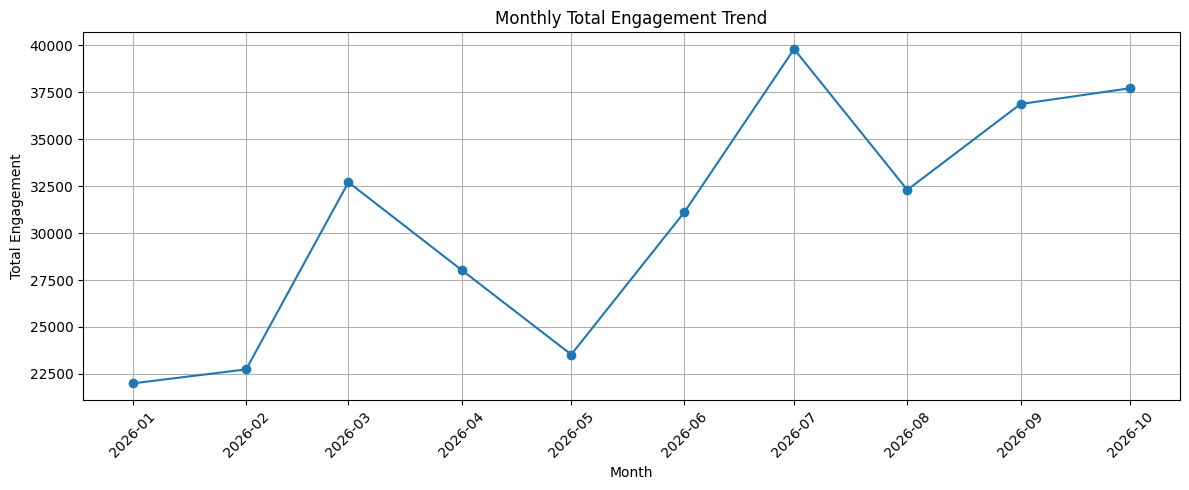

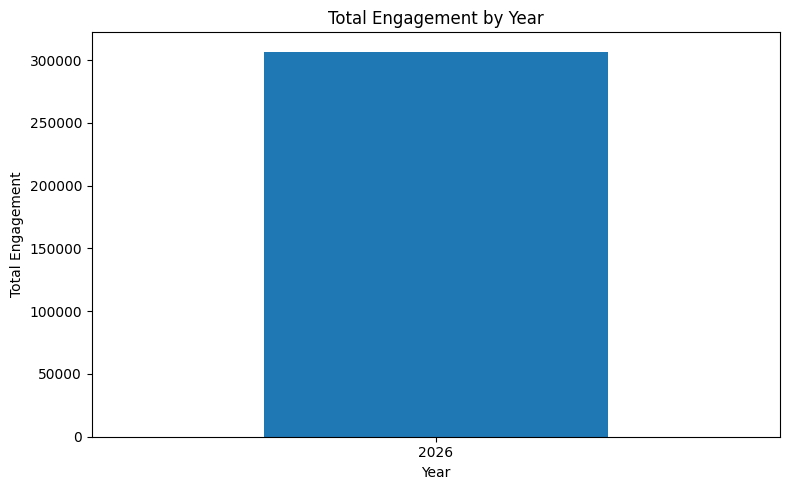

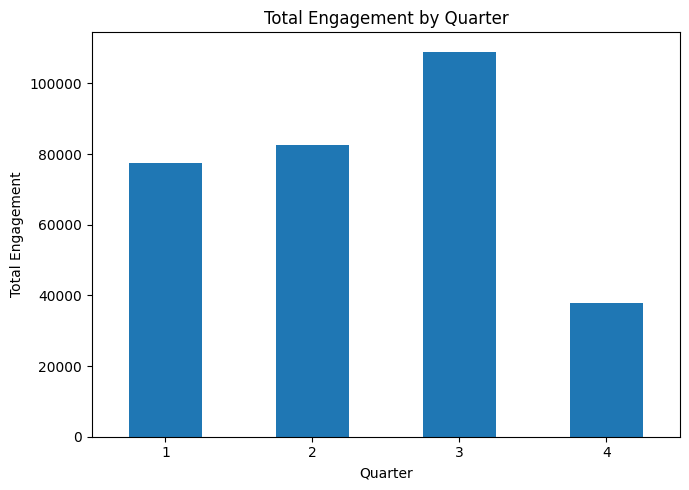

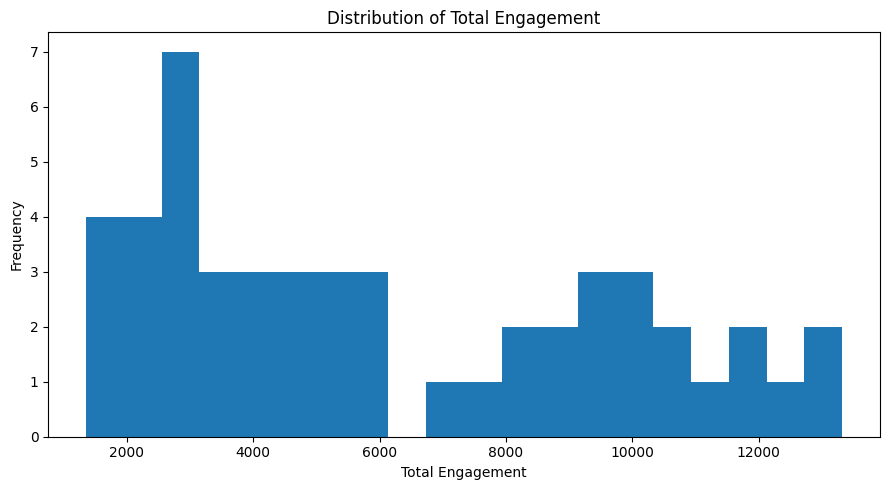

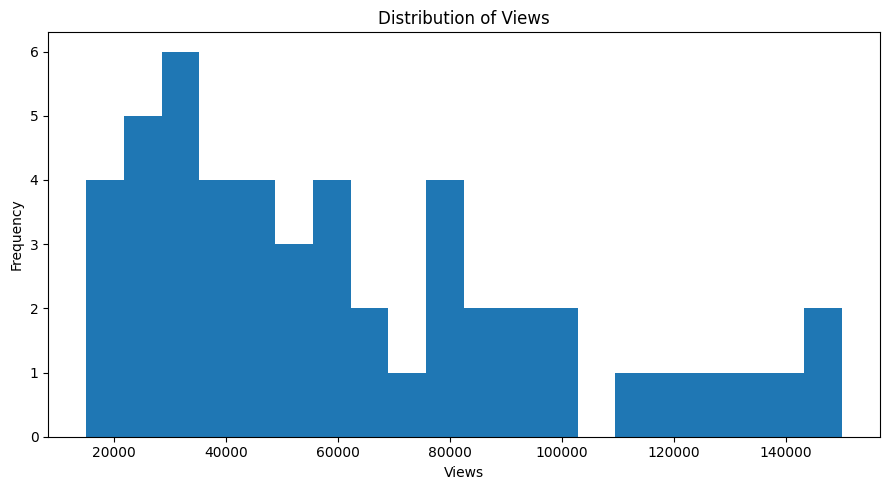

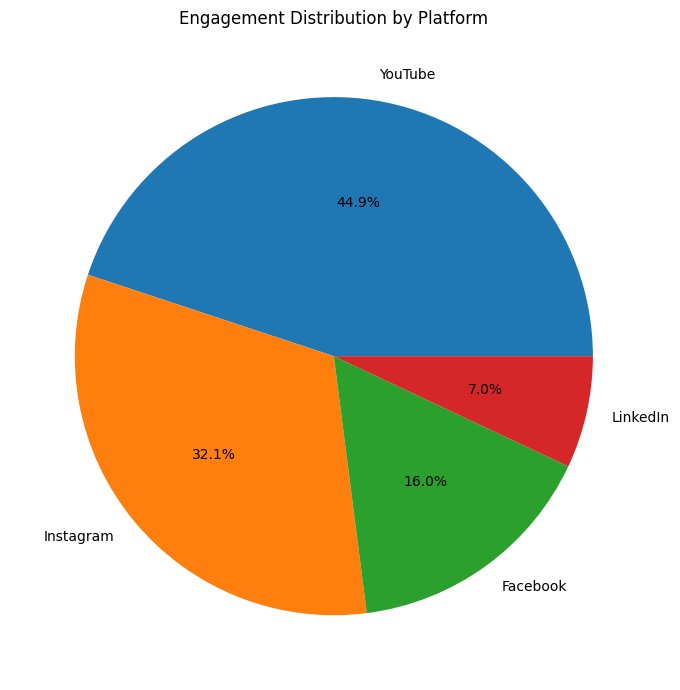


FINAL DATASET


,Post_ID,Platform,Post_Type,Date,Likes,Comments,Shares,Views,Followers,Total Engagement,Engagement Rate,Year,Month,Month_Name,Quarter,Order_Month
0,1,Instagram,Reel,2026-01-03,5200,310,480,52000,12000,5990,11.519231,2026,1,January,1,2026-01-01
1,2,YouTube,Video,2026-01-08,7100,520,620,82000,25000,8240,10.048780,2026,1,January,1,2026-01-01
2,3,Facebook,Video,2026-01-12,3400,190,260,43000,18000,3850,8.953488,2026,1,January,1,2026-01-01
3,4,Instagram,Image,2026-01-18,2300,120,140,28000,12000,2560,9.142857,2026,1,January,1,2026-01-01
4,5,LinkedIn,Post,2026-01-25,1200,85,70,15000,9000,1355,9.033333,2026,1,January,1,2026-01-01



Final Shape: (50, 16)

Final Columns:
['Post_ID', 'Platform', 'Post_Type', 'Date', 'Likes', 'Comments', 'Shares', 'Views', 'Followers', 'Total Engagement', 'Engagement Rate', 'Year', 'Month', 'Month_Name', 'Quarter', 'Order_Month']

Cleaned dataset saved as:
cleaned_social_media_data.csv

ANALYSIS COMPLETED SUCCESSFULLY!


In [5]:
# ============================================================
# SOCIAL MEDIA ANALYTICS - FDVA MINI PROJECT
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# 1. LOAD DATASET
# ============================================================

df = pd.read_csv("social_media_data.csv")

print("=" * 60)
print("SOCIAL MEDIA ANALYTICS")
print("=" * 60)

print("\nOriginal Columns:")
print(df.columns.tolist())

print("\nDataset Shape:", df.shape)

display(df.head())


# ============================================================
# 2. CLEAN COLUMN NAMES
# ============================================================

# Remove extra spaces from column names
df.columns = df.columns.str.strip()

print("\nCleaned Columns:")
print(df.columns.tolist())


# ============================================================
# 3. CHECK MISSING VALUES
# ============================================================

print("\n" + "=" * 60)
print("MISSING VALUES")
print("=" * 60)

print(df.isnull().sum())


# ============================================================
# 4. REMOVE DUPLICATES
# ============================================================

print("\nDuplicate Rows:", df.duplicated().sum())

df = df.drop_duplicates()

print("Rows after removing duplicates:", df.shape[0])


# ============================================================
# 5. CHECK REQUIRED COLUMNS
# ============================================================

print("\n" + "=" * 60)
print("AVAILABLE COLUMNS")
print("=" * 60)

for column in df.columns:
    print("-", column)


# ============================================================
# 6. CREATE TOTAL ENGAGEMENT IF NOT AVAILABLE
# ============================================================

if "Total Engagement" not in df.columns:

    print("\nTotal Engagement column not found.")
    print("Creating Total Engagement from Likes + Comments + Shares...")

    df["Total Engagement"] = (
        df["Likes"].fillna(0)
        + df["Comments"].fillna(0)
        + df["Shares"].fillna(0)
    )

else:

    print("\nTotal Engagement column already exists.")


# ============================================================
# 7. CREATE ENGAGEMENT RATE IF NOT AVAILABLE
# ============================================================

if "Engagement Rate" not in df.columns:

    print("Engagement Rate column not found.")
    print("Creating Engagement Rate...")

    df["Engagement Rate"] = np.where(
        df["Views"] != 0,
        (df["Total Engagement"] / df["Views"]) * 100,
        0
    )

else:

    print("Engagement Rate column already exists.")


# ============================================================
# 8. DATE PROCESSING
# ============================================================

if "Date" in df.columns:

    df["Date"] = pd.to_datetime(
        df["Date"],
        errors="coerce"
    )

    df["Year"] = df["Date"].dt.year

    df["Month"] = df["Date"].dt.month

    df["Month_Name"] = df["Date"].dt.month_name()

    df["Quarter"] = df["Date"].dt.quarter

    df["Order_Month"] = (
        df["Date"]
        .dt.to_period("M")
        .dt.to_timestamp()
    )


# ============================================================
# 9. KPI CALCULATIONS
# ============================================================

total_views = df["Views"].sum()

total_likes = df["Likes"].sum()

total_comments = df["Comments"].sum()

total_shares = df["Shares"].sum()

total_engagement = df["Total Engagement"].sum()

total_followers = df["Followers"].sum()

total_posts = df["Post_ID"].nunique()

average_engagement_rate = df["Engagement Rate"].mean()

average_views = df["Views"].mean()

average_followers = df["Followers"].mean()

average_engagement = df["Total Engagement"].mean()


# ============================================================
# 10. DISPLAY KPI VALUES
# ============================================================

print("\n" + "=" * 60)
print("KPI VALUES")
print("=" * 60)

print("Total Views              :", f"{total_views:,.0f}")

print("Total Likes              :", f"{total_likes:,.0f}")

print("Total Comments           :", f"{total_comments:,.0f}")

print("Total Shares             :", f"{total_shares:,.0f}")

print("Total Engagement         :", f"{total_engagement:,.0f}")

print("Total Followers          :", f"{total_followers:,.0f}")

print("Total Posts              :", total_posts)

print(
    "Average Engagement Rate  :",
    round(average_engagement_rate, 2)
)

print(
    "Average Views            :",
    round(average_views, 2)
)

print(
    "Average Followers        :",
    round(average_followers, 2)
)

print(
    "Average Engagement       :",
    round(average_engagement, 2)
)


# ============================================================
# 11. DESCRIPTIVE STATISTICS
# ============================================================

print("\n" + "=" * 60)
print("DESCRIPTIVE STATISTICS")
print("=" * 60)

print("\nTotal Engagement Statistics")

print("Mean:",
      round(df["Total Engagement"].mean(), 2))

print("Median:",
      round(df["Total Engagement"].median(), 2))

print("Mode:",
      round(df["Total Engagement"].mode()[0], 2))

print("Variance:",
      round(df["Total Engagement"].var(), 2))

print("Standard Deviation:",
      round(df["Total Engagement"].std(), 2))

print("Minimum:",
      round(df["Total Engagement"].min(), 2))

print("Maximum:",
      round(df["Total Engagement"].max(), 2))

print("Range:",
      round(
          df["Total Engagement"].max()
          - df["Total Engagement"].min(),
          2
      ))


# ============================================================
# 12. PLATFORM ANALYSIS
# ============================================================

platform_engagement = (
    df.groupby("Platform")["Total Engagement"]
    .sum()
    .sort_values(ascending=False)
)

platform_views = (
    df.groupby("Platform")["Views"]
    .sum()
    .sort_values(ascending=False)
)

platform_likes = (
    df.groupby("Platform")["Likes"]
    .sum()
    .sort_values(ascending=False)
)

platform_comments = (
    df.groupby("Platform")["Comments"]
    .sum()
    .sort_values(ascending=False)
)

platform_shares = (
    df.groupby("Platform")["Shares"]
    .sum()
    .sort_values(ascending=False)
)

platform_followers = (
    df.groupby("Platform")["Followers"]
    .sum()
    .sort_values(ascending=False)
)

platform_engagement_rate = (
    df.groupby("Platform")["Engagement Rate"]
    .mean()
    .sort_values(ascending=False)
)


# ============================================================
# 13. POST TYPE ANALYSIS
# ============================================================

post_type_engagement = (
    df.groupby("Post_Type")["Total Engagement"]
    .sum()
    .sort_values(ascending=False)
)

post_type_views = (
    df.groupby("Post_Type")["Views"]
    .sum()
    .sort_values(ascending=False)
)


# ============================================================
# 14. DATE ANALYSIS
# ============================================================

yearly_engagement = (
    df.groupby("Year")["Total Engagement"]
    .sum()
    .sort_index()
)

monthly_engagement = (
    df.groupby("Order_Month")["Total Engagement"]
    .sum()
    .sort_index()
)

quarter_engagement = (
    df.groupby("Quarter")["Total Engagement"]
    .sum()
    .sort_index()
)


# ============================================================
# 15. DISPLAY PLATFORM ANALYSIS
# ============================================================

print("\n" + "=" * 60)
print("PLATFORM ANALYSIS")
print("=" * 60)

print("\nTotal Engagement by Platform:")
print(platform_engagement)

print("\nTotal Views by Platform:")
print(platform_views)

print("\nTotal Likes by Platform:")
print(platform_likes)

print("\nTotal Comments by Platform:")
print(platform_comments)

print("\nTotal Shares by Platform:")
print(platform_shares)

print("\nTotal Followers by Platform:")
print(platform_followers)

print("\nAverage Engagement Rate by Platform:")
print(platform_engagement_rate)


# ============================================================
# 16. POST TYPE ANALYSIS
# ============================================================

print("\n" + "=" * 60)
print("POST TYPE ANALYSIS")
print("=" * 60)

print("\nEngagement by Post Type:")
print(post_type_engagement)

print("\nViews by Post Type:")
print(post_type_views)


# ============================================================
# 17. TIME ANALYSIS
# ============================================================

print("\n" + "=" * 60)
print("TIME ANALYSIS")
print("=" * 60)

print("\nEngagement by Year:")
print(yearly_engagement)

print("\nEngagement by Quarter:")
print(quarter_engagement)

print("\nMonthly Engagement:")
print(monthly_engagement)


# ============================================================
# 18. KEY INSIGHTS
# ============================================================

print("\n" + "=" * 60)
print("KEY INSIGHTS")
print("=" * 60)

print(
    "Best Platform by Engagement:",
    platform_engagement.idxmax()
)

print(
    "Best Platform by Views:",
    platform_views.idxmax()
)

print(
    "Best Platform by Followers:",
    platform_followers.idxmax()
)

print(
    "Best Platform by Engagement Rate:",
    platform_engagement_rate.idxmax()
)

print(
    "Best Post Type:",
    post_type_engagement.idxmax()
)

print(
    "Best Year:",
    yearly_engagement.idxmax()
)


# ============================================================
# 19. VISUALIZATION 1
# TOTAL ENGAGEMENT BY PLATFORM
# ============================================================

plt.figure(figsize=(8, 5))

platform_engagement.plot(kind="bar")

plt.title("Total Engagement by Platform")
plt.xlabel("Platform")
plt.ylabel("Total Engagement")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()


# ============================================================
# 20. VISUALIZATION 2
# AVERAGE ENGAGEMENT RATE BY PLATFORM
# ============================================================

plt.figure(figsize=(8, 5))

platform_engagement_rate.plot(kind="bar")

plt.title("Average Engagement Rate by Platform")
plt.xlabel("Platform")
plt.ylabel("Average Engagement Rate (%)")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()


# ============================================================
# 21. VISUALIZATION 3
# TOTAL FOLLOWERS BY PLATFORM
# ============================================================

plt.figure(figsize=(8, 5))

platform_followers.plot(kind="bar")

plt.title("Total Followers by Platform")
plt.xlabel("Platform")
plt.ylabel("Followers")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()


# ============================================================
# 22. VISUALIZATION 4
# TOTAL ENGAGEMENT BY POST TYPE
# ============================================================

plt.figure(figsize=(8, 5))

post_type_engagement.plot(kind="bar")

plt.title("Total Engagement by Post Type")
plt.xlabel("Post Type")
plt.ylabel("Total Engagement")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


# ============================================================
# 23. VISUALIZATION 5
# MONTHLY ENGAGEMENT TREND
# ============================================================

plt.figure(figsize=(12, 5))

plt.plot(
    monthly_engagement.index,
    monthly_engagement.values,
    marker="o"
)

plt.title("Monthly Total Engagement Trend")
plt.xlabel("Month")
plt.ylabel("Total Engagement")

plt.xticks(rotation=45)

plt.grid(True)

plt.tight_layout()
plt.show()


# ============================================================
# 24. VISUALIZATION 6
# YEARLY ENGAGEMENT
# ============================================================

plt.figure(figsize=(8, 5))

yearly_engagement.plot(kind="bar")

plt.title("Total Engagement by Year")
plt.xlabel("Year")
plt.ylabel("Total Engagement")

plt.xticks(rotation=0)

plt.tight_layout()
plt.show()


# ============================================================
# 25. VISUALIZATION 7
# QUARTERLY ENGAGEMENT
# ============================================================

plt.figure(figsize=(7, 5))

quarter_engagement.plot(kind="bar")

plt.title("Total Engagement by Quarter")
plt.xlabel("Quarter")
plt.ylabel("Total Engagement")

plt.xticks(rotation=0)

plt.tight_layout()
plt.show()


# ============================================================
# 26. VISUALIZATION 8
# ENGAGEMENT DISTRIBUTION
# ============================================================

plt.figure(figsize=(9, 5))

plt.hist(
    df["Total Engagement"],
    bins=20
)

plt.title("Distribution of Total Engagement")
plt.xlabel("Total Engagement")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()


# ============================================================
# 27. VISUALIZATION 9
# VIEWS DISTRIBUTION
# ============================================================

plt.figure(figsize=(9, 5))

plt.hist(
    df["Views"],
    bins=20
)

plt.title("Distribution of Views")
plt.xlabel("Views")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()


# ============================================================
# 28. VISUALIZATION 10
# ENGAGEMENT DISTRIBUTION BY PLATFORM
# ============================================================

plt.figure(figsize=(7, 7))

platform_engagement.plot(
    kind="pie",
    autopct="%1.1f%%"
)

plt.title("Engagement Distribution by Platform")
plt.ylabel("")

plt.tight_layout()
plt.show()


# ============================================================
# 29. FINAL DATASET
# ============================================================

print("\n" + "=" * 60)
print("FINAL DATASET")
print("=" * 60)

display(df.head())

print("\nFinal Shape:", df.shape)

print("\nFinal Columns:")
print(df.columns.tolist())


# ============================================================
# 30. SAVE CLEANED DATASET
# ============================================================

df.to_csv(
    "cleaned_social_media_data.csv",
    index=False
)

print("\nCleaned dataset saved as:")
print("cleaned_social_media_data.csv")

print("\n" + "=" * 60)
print("ANALYSIS COMPLETED SUCCESSFULLY!")
print("=" * 60)